In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [2]:
#df=pd.read_excel('cgpaPRED.xls')
#df.to_csv('cgpaPRED.csv', index=False)

In [3]:
df=pd.read_csv("cgpaPRED.csv")

In [4]:
df.shape

(331, 5)

In [5]:
df.describe()

,SEM 1,SEM 2,SEM 3,SEM 4,SEM 5
count,331.000000,331.000000,331.000000,331.000000,331.000000
mean,6.751057,6.873746,6.960000,7.041631,6.907915
std,2.393484,2.336872,2.248007,2.275969,2.264617
min,0.100000,0.100000,0.130000,0.120000,0.140000
25%,5.990000,6.340000,6.510000,6.700000,6.465000
50%,7.330000,7.540000,7.680000,7.710000,7.600000
75%,8.360000,8.500000,8.350000,8.500000,8.320000
max,9.800000,9.880000,9.730000,9.880000,9.640000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 331 entries, 0 to 330
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEM 1   331 non-null    float64
 1   SEM 2   331 non-null    float64
 2   SEM 3   331 non-null    float64
 3   SEM 4   331 non-null    float64
 4   SEM 5   331 non-null    float64
dtypes: float64(5)
memory usage: 13.1 KB


In [7]:
df.columns

Index(['SEM 1', 'SEM 2', 'SEM 3', 'SEM 4', 'SEM 5'], dtype='object')

# Understanding the dataset
The dataset cgpaPRED.csv have a total of 5 columns out of which 4 are input features('SEM 1', 'SEM 2', 'SEM 3', 'SEM 4') and 1 output feature('SEM 5). 
There are around 48 rows which are repeted, So we need to remove so that we do not face any problem

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df = df.drop_duplicates()
df.shape

(331, 5)

In [10]:
df

,SEM 1,SEM 2,SEM 3,SEM 4,SEM 5
0,6.60,7.60,6.90,7.22,7.08
1,7.77,7.22,7.00,7.90,7.47
2,6.90,6.00,7.12,7.54,6.89
3,5.50,6.60,6.70,6.50,6.33
4,7.20,6.00,7.21,7.70,7.03
...,...,...,...,...,...
326,0.54,0.78,0.45,0.98,0.69
327,0.80,0.19,0.52,0.83,0.59
328,0.88,0.78,0.43,0.32,0.60
329,4.23,4.32,4.96,4.39,4.48


In [11]:
df.notna().sum()

SEM 1    331
SEM 2    331
SEM 3    331
SEM 4    331
SEM 5    331
dtype: int64

In [12]:
df.isnull().sum()

SEM 1    0
SEM 2    0
SEM 3    0
SEM 4    0
SEM 5    0
dtype: int64

# TRAIN / TEST SPLIT
Splitting the data here (as part of EDA) so the same split is reused for both Simple Linear Regression and Multiple Linear Regression, instead of splitting again in each section.

In [13]:
X = df[['SEM 1', 'SEM 2', 'SEM 3', 'SEM 4']]
y = df['SEM 5']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Simple Linear Regression will use only SEM 1 from this same split
X_train_simple = X_train[['SEM 1']]
X_test_simple = X_test[['SEM 1']]


# VISUALIZATION

In [14]:
a = df["SEM 1"]
b = df["SEM 5"]

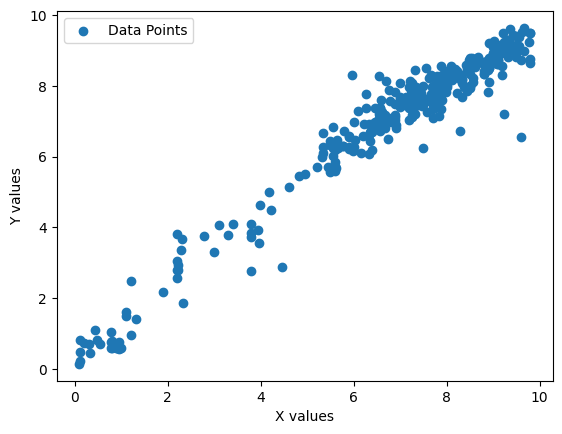

In [15]:
plt.scatter(a,b,label='Data Points')
plt.xlabel("X values")
plt.ylabel("Y values")
plt.legend()
plt.show()

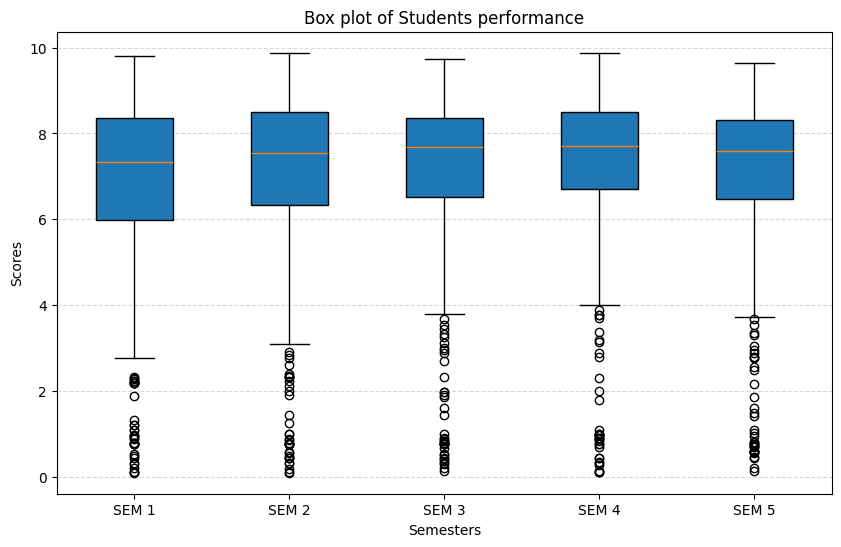

In [16]:
semesterCols = ["SEM 1", "SEM 2", "SEM 3", "SEM 4", "SEM 5"]
dataToPolot = [df[col].dropna() for col in semesterCols]
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(dataToPolot, tick_labels=semesterCols, patch_artist=True)
ax.set_title("Box plot of Students performance")
ax.set_xlabel("Semesters")
ax.set_ylabel("Scores")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

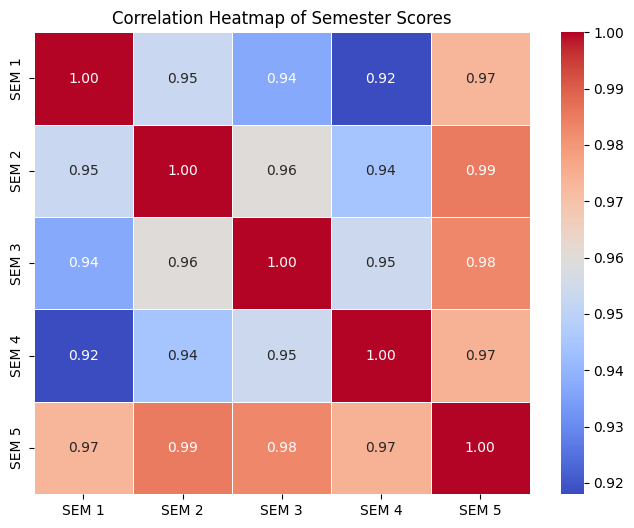

In [17]:
semesterCols = ["SEM 1", "SEM 2", "SEM 3", "SEM 4", "SEM 5"]

corrMatrix = df[semesterCols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corrMatrix,
    annot=True,      # show correlation values
    cmap="coolwarm", # color scheme
    fmt=".2f",       # 2 decimal places
    linewidths=0.5
)

plt.title("Correlation Heatmap of Semester Scores")
plt.show()

In [18]:
corrWithLabel = corrMatrix["SEM 5"].sort_values(ascending=False)
print("Correlation of each feature with SEM 5 (label):")
print(corrWithLabel)


Correlation of each feature with SEM 5 (label):
SEM 5    1.000000
SEM 2    0.985253
SEM 3    0.982953
SEM 4    0.974067
SEM 1    0.973233
Name: SEM 5, dtype: float64


# CODE OF LINEAR REGRESSION

In [19]:
model = LinearRegression()
model.fit(X_train_simple, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [20]:
y_pred = model.predict(X_test_simple)


In [21]:
print("\nRegression Equation:")

print(
    f"Y = {model.intercept_:.2f} + "
    f"{model.coef_[0]:.2f}X1"
)


Regression Equation:
Y = 0.68 + 0.92X1


In [22]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

if len(y_test) > 1:
    r2 = r2_score(y_test, y_pred)
else:
    r2 = 0

In [23]:
print("MODEL PERFORMANCE")

print(f"MSE  : {mse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MODEL PERFORMANCE
MSE  : 0.1842
MAE  : 0.3209
RMSE : 0.4292
R²   : 0.9676


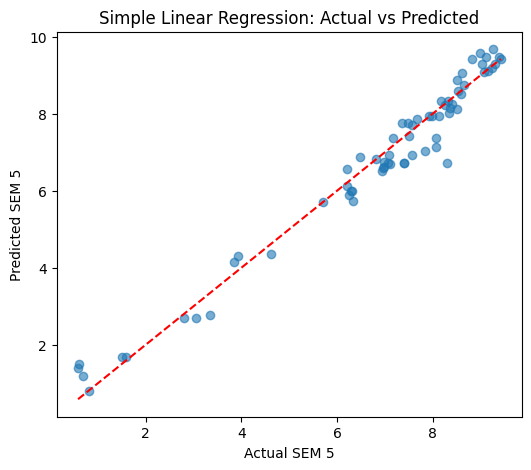

In [24]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual SEM 5")
plt.ylabel("Predicted SEM 5")
plt.title("Simple Linear Regression: Actual vs Predicted")
plt.show()


# CODE OF MULTIPLE LINEAR REGRESSION

In [25]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [26]:
y_pred = model.predict(X_test)

In [27]:
print("Regression Equation:")

print(
    f"Y = {model.intercept_:.2f} + "
    f"{model.coef_[0]:.2f}X1 + "
    f"{model.coef_[1]:.2f}X2 + "
    f"{model.coef_[2]:.2f}X3 + "
    f"{model.coef_[3]:.2f}X4"
)


Regression Equation:
Y = 0.00 + 0.25X1 + 0.25X2 + 0.25X3 + 0.25X4


In [28]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

if len(y_test) > 1:
    r2 = r2_score(y_test, y_pred)
else:
    r2 = 0

In [29]:
print("MODEL PERFORMANCE")
print(f"MSE  : {mse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MODEL PERFORMANCE
MSE  : 0.0000
MAE  : 0.0026
RMSE : 0.0029
R²   : 1.0000


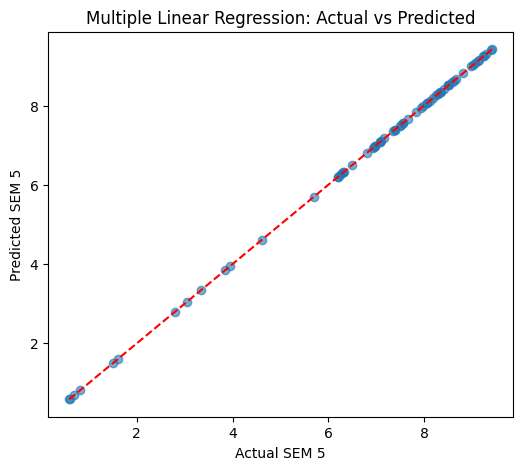

In [30]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual SEM 5")
plt.ylabel("Predicted SEM 5")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.show()


In [31]:
# Check whether SEM 5 is arithmetically derived from SEM 1-4
df['SEM5_check'] = df[['SEM 1', 'SEM 2', 'SEM 3', 'SEM 4']].mean(axis=1)
comparison = df[['SEM 5', 'SEM5_check']].copy()
comparison['difference'] = comparison['SEM 5'] - comparison['SEM5_check']
print(comparison.describe())


            SEM 5  SEM5_check    difference
count  331.000000  331.000000  3.310000e+02
mean     6.907915    6.906609  1.306647e-03
std      2.264617    2.264616  2.802123e-03
min      0.140000    0.135000 -2.500000e-03
25%      6.465000    6.461250 -1.776357e-15
50%      7.600000    7.597500  1.776357e-15
75%      8.320000    8.321250  5.000000e-03
max      9.640000    9.637500  5.000000e-03


### Note on R² = 1.0000
The Multiple Linear Regression model achieves a near-perfect R² because SEM 5 in this dataset is (approximately) the arithmetic mean of SEM 1-4, as shown by the near-zero 'difference' column above. This is not overfitting or a modeling achievement — the label is deterministically derived from the features. Simple Linear Regression (R² ≈ 0.97, using only SEM 1) reflects a more realistic single-feature predictive scenario.